# Spotify Song Popularity — Notebook 3: Audio Features

IS 507 Midterm Project (version 5). This notebook describes the nine audio features of the audio dataset from Notebook 1 and their association with popularity.

## Notebook Outline

| Section | Content | Main outputs | Report reference |
|---|---|---|---|
| 1 | Setup and the list of audio features | `AUDIO_FEATURES` | Section 4.1 |
| 2 | Loading the audio dataset (171,510 songs): overview, required columns, type conversion, preview | `df` | Table 2 |
| 3 | Distribution of popularity | Histogram with mean and median | Section 4.3 |
| 4 | Descriptive statistics and distributions of the nine audio features | Summary table, 3 × 3 histograms | Section 4.1 |
| 5 | Pearson correlation matrix of the audio features and popularity | Heat map | Figure 4 (right) |



Run the cells in order. The audio dataset must first be exported by Notebook 1.

## 1. Setup

The packages for data handling (`pandas`, `numpy`), visualization (`matplotlib`, `seaborn`), correlation tests (`scipy.stats.pearsonr`), multiple-comparison correction (`statsmodels`), and standardization (`StandardScaler`) are loaded, and the random seed is fixed for reproducibility.

In [1]:
import os
import math
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

The nine Spotify audio features used throughout the notebook are defined in `AUDIO_FEATURES`. `LEAKAGE_COLS` lists the artist-level variables (mean artist popularity and follower count) that are kept in the file but never used as model inputs, because they are largely computed from song popularity (data leakage).

In [2]:
AUDIO_FEATURES = [
    "danceability", "energy", "loudness",
    "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo",
]
LEAKAGE_COLS = ["avg_artist_popularity", "total_artist_followers"]
print("Audio features:", AUDIO_FEATURES)

Audio features: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']


## 2. Load the Audio Dataset

Google Drive is mounted and the project folders (`data/`, `figures/`, `results/`) are created if they do not exist.

In [3]:
# [COLAB_ONLY] Run this cell in Colab only
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/IS507_Spotify_Project"
DATA_DIR = f"{PROJECT_DIR}/data"
FIG_DIR = f"{PROJECT_DIR}/figures"
RESULT_DIR = f"{PROJECT_DIR}/results"
for d in [DATA_DIR, FIG_DIR, RESULT_DIR]:
    os.makedirs(d, exist_ok=True)
print("Output folder:", PROJECT_DIR)

Mounted at /content/drive
Output folder: /content/drive/MyDrive/IS507_Spotify_Project


`RAW_PATH` points to `songs_clean_audio.csv`, the audio dataset exported by Notebook 1 (all cleaned songs, including songs without valid lyrics).

In [4]:
RAW_PATH = f"{DATA_DIR}/songs_clean_audio.csv"

The CSV file is read into a DataFrame; the number of rows and columns, the column names, and the first rows are displayed.

In [5]:
t0 = time.time()
raw = pd.read_csv(RAW_PATH, low_memory=False)
print(f"Loaded: {raw.shape[0]:,} rows × {raw.shape[1]} columns ({time.time() - t0:.1f} s)")
print("\nColumns:", list(raw.columns))
raw.head(10)

Loaded: 171,510 rows × 32 columns (3.2 s)

Columns: ['id', 'name', 'artists', 'main_artist', 'album_name', 'year', 'first_year', 'genre', 'popularity', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'avg_artist_popularity', 'total_artist_followers', 'era', 'has_lyrics', 'lyrics_n_words', 'en_stopword_ratio', 'non_ascii_ratio', 'lyrics_group_id', 'split', 'split_random', 'split_artist_group', 'split_temporal', 'artist_cluster', 'artist_seen_in_train']


,id,name,artists,main_artist,album_name,year,first_year,genre,popularity,danceability,energy,loudness,speechiness,acousticness,instrumentalness,...,tempo,avg_artist_popularity,total_artist_followers,era,has_lyrics,lyrics_n_words,en_stopword_ratio,non_ascii_ratio,lyrics_group_id,split,split_random,split_artist_group,split_temporal,artist_cluster,artist_seen_in_train
0,0005VnpISGYLSGrXg9TEJS,Space Loneliness,"[""SadDoLLs""]",saddolls,About Darkness,2009,2009,Rock,1,0.2970,0.2760,-10.9370,0.0410,0.4650,0.7630,...,125.1590,25.0000,5514,2009-2012,1,60,0.4394,0.0000,ef97b8b48a9f90e13559f4913a039e78da0ed84dd1d5ef...,train,train,test,train,12174,1
1,000cAxMxUfuDlvPYIVrrZ4,Mind Control,"[""Tantric""]",tantric,Mind Control,2009,2009,Rock,27,0.4740,0.9660,-2.9570,0.0931,0.0001,0.0000,...,156.9930,46.0000,230680,2009-2012,1,198,0.4478,0.0000,71638a94a6b5c82cc8cad8fd5bbfcbe4ba693265129183...,val,val,train,train,7226,1
2,003KqHsoqMVwh3BnGNvNBs,Hard To Be Vain,"[""Vains Of Jenna""]",vains of jenna,Lit Up / Let Down,2009,2009,Rock,14,0.3930,0.7210,-9.4360,0.0438,0.0000,0.5430,...,131.9330,35.0000,19978,2009-2012,1,369,0.5509,0.0000,0b0b1e40a51f5b9b3b969741cc5d6775f333760bdbc9af...,train,train,train,train,13528,1
3,007AWm6uGtVnUEKP0ysNaE,Daddy,"[""The Maytals""]",the maytals,The Sensational Maytals,2009,2009,Folk,8,0.4670,0.4830,-6.7530,0.0456,0.1940,0.0000,...,163.5450,33.0000,77436,2009-2012,1,189,0.5969,0.0000,3ba29e5f7194d3b04732cbe2f3186db4a42a594f145854...,train,train,train,train,22043,1
4,00AyA0C53vF1UqJhn6DnHg,Quartet (A Model of Decorum and Tranquility),"[""Chess In Concert""]",chess in concert,Chess In Concert,2009,2009,Classical,28,0.6300,0.3340,-11.6050,0.4020,0.8790,0.0000,...,128.6840,39.0000,249,2009-2012,1,381,0.5313,0.0000,be6c5db8c7b55c182063743e590bd81d6c79b85173834d...,train,train,val,train,6730,1
5,00LKsykhv7ZXFBPeR33oQD,I Bowed On My Knees - Live,"[""Michael English"", ""Mark Lowry"", ""Guy Penrod""...",michael english,Gaither Vocal Band - Reunion,2009,2009,Country,26,0.2790,0.2760,-10.6230,0.0341,0.7110,0.0000,...,135.1330,36.8000,271306,2009-2012,1,91,0.4457,0.0000,3c7ff0e15976cad2404ccbb2d28dd333431b5195305a9d...,train,train,train,train,14479,1
6,00OHAIQVi1hj4NHHfrPLJj,Only Have One,"[""JJ Heller""]",jj heller,Painted Red,2009,2009,Folk,9,0.6200,0.2540,-10.2630,0.0364,0.7490,0.0000,...,74.9970,58.0000,164443,2009-2012,1,139,0.6972,0.0000,467c5f3fa3c4640818286260c8ec3f87219c6f8b8d5f4d...,val,val,train,train,3233,1
7,00PjPozDzCqaoY9phHkVeK,Burn This Love,"[""Ex-Voto""]",ex-voto,Antioch,2009,2009,Rock,5,0.5420,0.8780,-9.8790,0.0373,0.0006,0.0150,...,130.0220,20.0000,13825,2009-2012,1,190,0.6053,0.0000,b81c6d134a69a48a7514cd07cf085bbb54c34262927e79...,val,val,train,train,22942,0
8,00QNQicWMCTz24SR63M89B,Seeing Hands - Sleepwalking Version,"[""Dengue Fever""]",dengue fever,Dengue Fever Presents: Sleepwalking Through th...,2009,2009,Jazz,6,0.4400,0.2470,-16.1180,0.0287,0.8350,0.8530,...,74.1920,32.0000,55767,2009-2012,1,125,0.5758,0.0000,7991fcf2434d69d18412c954569616c1f4c295d8955850...,train,train,train,train,22337,1
9,00Rwe3aMRy3gKxtdoLJY0C,Way Of The World,"[""Wishbone Ash""]",wishbone ash,40th Anniversary Concert - Live In London,2009,2009,Rock,4,0.3550,0.8920,-7.3010,0.0800,0.0051,0.0286,...,147.3790,44.0000,230357,2009-2012,1,115,0.5378,0.0000,a62f63f8203443392a3c2c43f3a70375b1eea379089974...,train,train,train,train,15371,1


The overview table reports, for each column, the data type, the number and share of missing values, and the number of distinct values.

In [6]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_n": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(2),
    "n_unique": raw.nunique(),
})
overview

,dtype,missing_n,missing_pct,n_unique
id,object,0,0.0000,171510
name,object,1,0.0000,133371
artists,object,0,0.0000,52115
main_artist,object,0,0.0000,25712
album_name,object,10,0.0100,61311
year,int64,0,0.0000,17
first_year,int64,0,0.0000,17
genre,object,0,0.0000,10
popularity,int64,0,0.0000,93
danceability,float64,0,0.0000,1159


The required columns (identifiers, year, genre, popularity, and the nine audio features) are checked before the analysis.

In [7]:
REQUIRED = ["id", "name", "artists", "year", "genre", "popularity"] + AUDIO_FEATURES
missing_cols = [c for c in REQUIRED if c not in raw.columns]
if missing_cols:
    print("Missing columns:", missing_cols)
    print("   → Rename the columns with raw = raw.rename(columns={'old_name': 'new_name'}) and re-run")
else:
    print("All required columns are present")

All required columns are present


A working copy `df` is created, and the audio features, popularity, year, and the artist-level columns are converted to numeric types with `pd.to_numeric(errors="coerce")`; values that cannot be converted become NaN. The printed data types should all be `float64` or `int64`.

In [8]:
df = raw.copy()
numeric_cols = AUDIO_FEATURES + ["popularity", "year"] + [c for c in LEAKAGE_COLS if c in df.columns]
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["id"] = df["id"].astype(str)
print(df[AUDIO_FEATURES + ["popularity", "year"]].dtypes)

danceability        float64
energy              float64
loudness            float64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
popularity            int64
year                  int64
dtype: object


Preview of the song-level columns used in the analysis (identifiers, year, and artist-level variables are hidden).

In [9]:
df.drop(columns=["id", "artists", "album_name", "year", "avg_artist_popularity", "total_artist_followers"]).head(10)

,name,main_artist,first_year,genre,popularity,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,era,has_lyrics,lyrics_n_words,en_stopword_ratio,non_ascii_ratio,lyrics_group_id,split,split_random,split_artist_group,split_temporal,artist_cluster,artist_seen_in_train
0,Space Loneliness,saddolls,2009,Rock,1,0.2970,0.2760,-10.9370,0.0410,0.4650,0.7630,0.1070,0.0332,125.1590,2009-2012,1,60,0.4394,0.0000,ef97b8b48a9f90e13559f4913a039e78da0ed84dd1d5ef...,train,train,test,train,12174,1
1,Mind Control,tantric,2009,Rock,27,0.4740,0.9660,-2.9570,0.0931,0.0001,0.0000,0.3740,0.6020,156.9930,2009-2012,1,198,0.4478,0.0000,71638a94a6b5c82cc8cad8fd5bbfcbe4ba693265129183...,val,val,train,train,7226,1
2,Hard To Be Vain,vains of jenna,2009,Rock,14,0.3930,0.7210,-9.4360,0.0438,0.0000,0.5430,0.0662,0.4170,131.9330,2009-2012,1,369,0.5509,0.0000,0b0b1e40a51f5b9b3b969741cc5d6775f333760bdbc9af...,train,train,train,train,13528,1
3,Daddy,the maytals,2009,Folk,8,0.4670,0.4830,-6.7530,0.0456,0.1940,0.0000,0.1260,0.5800,163.5450,2009-2012,1,189,0.5969,0.0000,3ba29e5f7194d3b04732cbe2f3186db4a42a594f145854...,train,train,train,train,22043,1
4,Quartet (A Model of Decorum and Tranquility),chess in concert,2009,Classical,28,0.6300,0.3340,-11.6050,0.4020,0.8790,0.0000,0.7300,0.7080,128.6840,2009-2012,1,381,0.5313,0.0000,be6c5db8c7b55c182063743e590bd81d6c79b85173834d...,train,train,val,train,6730,1
5,I Bowed On My Knees - Live,michael english,2009,Country,26,0.2790,0.2760,-10.6230,0.0341,0.7110,0.0000,0.7740,0.2220,135.1330,2009-2012,1,91,0.4457,0.0000,3c7ff0e15976cad2404ccbb2d28dd333431b5195305a9d...,train,train,train,train,14479,1
6,Only Have One,jj heller,2009,Folk,9,0.6200,0.2540,-10.2630,0.0364,0.7490,0.0000,0.1130,0.3760,74.9970,2009-2012,1,139,0.6972,0.0000,467c5f3fa3c4640818286260c8ec3f87219c6f8b8d5f4d...,val,val,train,train,3233,1
7,Burn This Love,ex-voto,2009,Rock,5,0.5420,0.8780,-9.8790,0.0373,0.0006,0.0150,0.2380,0.4040,130.0220,2009-2012,1,190,0.6053,0.0000,b81c6d134a69a48a7514cd07cf085bbb54c34262927e79...,val,val,train,train,22942,0
8,Seeing Hands - Sleepwalking Version,dengue fever,2009,Jazz,6,0.4400,0.2470,-16.1180,0.0287,0.8350,0.8530,0.1150,0.0377,74.1920,2009-2012,1,125,0.5758,0.0000,7991fcf2434d69d18412c954569616c1f4c295d8955850...,train,train,train,train,22337,1
9,Way Of The World,wishbone ash,2009,Rock,4,0.3550,0.8920,-7.3010,0.0800,0.0051,0.0286,0.8360,0.1690,147.3790,2009-2012,1,115,0.5378,0.0000,a62f63f8203443392a3c2c43f3a70375b1eea379089974...,train,train,train,train,15371,1


## 3. Distribution of Popularity

Histogram of popularity with a kernel density estimate. The dashed line marks the mean and the dotted line the median; a mean above the median indicates a right-skewed distribution, which motivates the median baseline and MAE as the main metric.

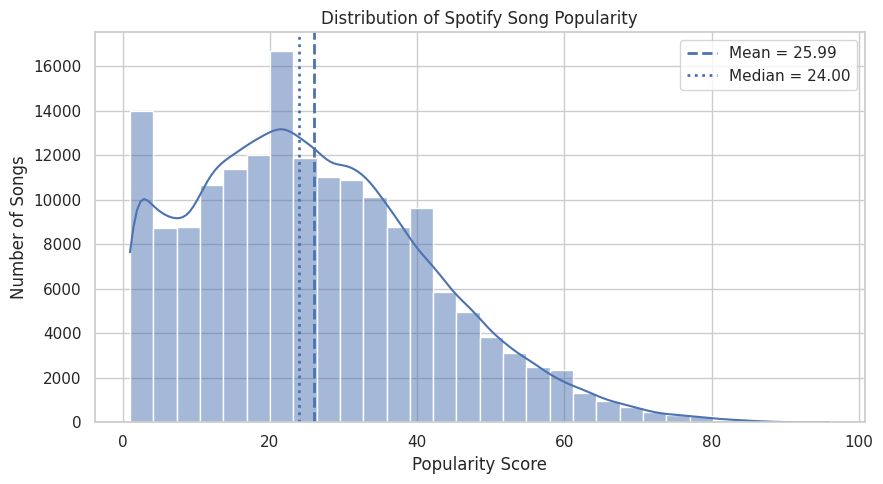

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=df,
    x="popularity",
    bins=30,
    kde=True,
    ax=ax
)

ax.axvline(
    df["popularity"].mean(),
    linestyle="--",
    linewidth=2,
    label=f'Mean = {df["popularity"].mean():.2f}'
)

ax.axvline(
    df["popularity"].median(),
    linestyle=":",
    linewidth=2,
    label=f'Median = {df["popularity"].median():.2f}'
)

ax.set_title("Distribution of Spotify Song Popularity")
ax.set_xlabel("Popularity Score")
ax.set_ylabel("Number of Songs")
ax.legend()

plt.tight_layout()
plt.show()

## 4. Descriptive Statistics and Feature Distributions

The cell reports the number of rows, the number of fully duplicated rows, missing values for popularity and each audio feature, and descriptive statistics (count, mean, standard deviation, minimum, quartiles, maximum).

In [11]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

print("Rows:", len(df))
print("Duplicated rows:", df.duplicated().sum())

print(df[["popularity"] + audio_features].isnull().sum())

summary = df[["popularity"] + audio_features].describe().T

print(summary)

Rows: 171510
Duplicated rows: 0
popularity          0
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
dtype: int64
                        count     mean     std      min      25%      50%  \
popularity       171,510.0000  25.9858 15.9671   1.0000  14.0000  24.0000   
danceability     171,510.0000   0.5290  0.1720   0.0548   0.4140   0.5300   
energy           171,510.0000   0.7022  0.2304   0.0000   0.5450   0.7450   
loudness         171,510.0000  -6.9297  3.2866 -39.5730  -8.4540  -6.2500   
speechiness      171,510.0000   0.0919  0.0948   0.0222   0.0364   0.0540   
acousticness     171,510.0000   0.2049  0.2852   0.0000   0.0019   0.0475   
instrumentalness 171,510.0000   0.1117  0.2449   0.0000   0.0000   0.0002   
liveness         171,510.0000   0.2102  0.1707   0.0067   0.1010   0.1380   
valence          171,510.0000   0.4187  0.

Histograms with kernel density estimates of the nine audio features in a 3 × 3 grid. All features except loudness (dB) and tempo (BPM) lie between 0 and 1; skewed features such as speechiness, instrumentalness, and liveness are concentrated near 0.

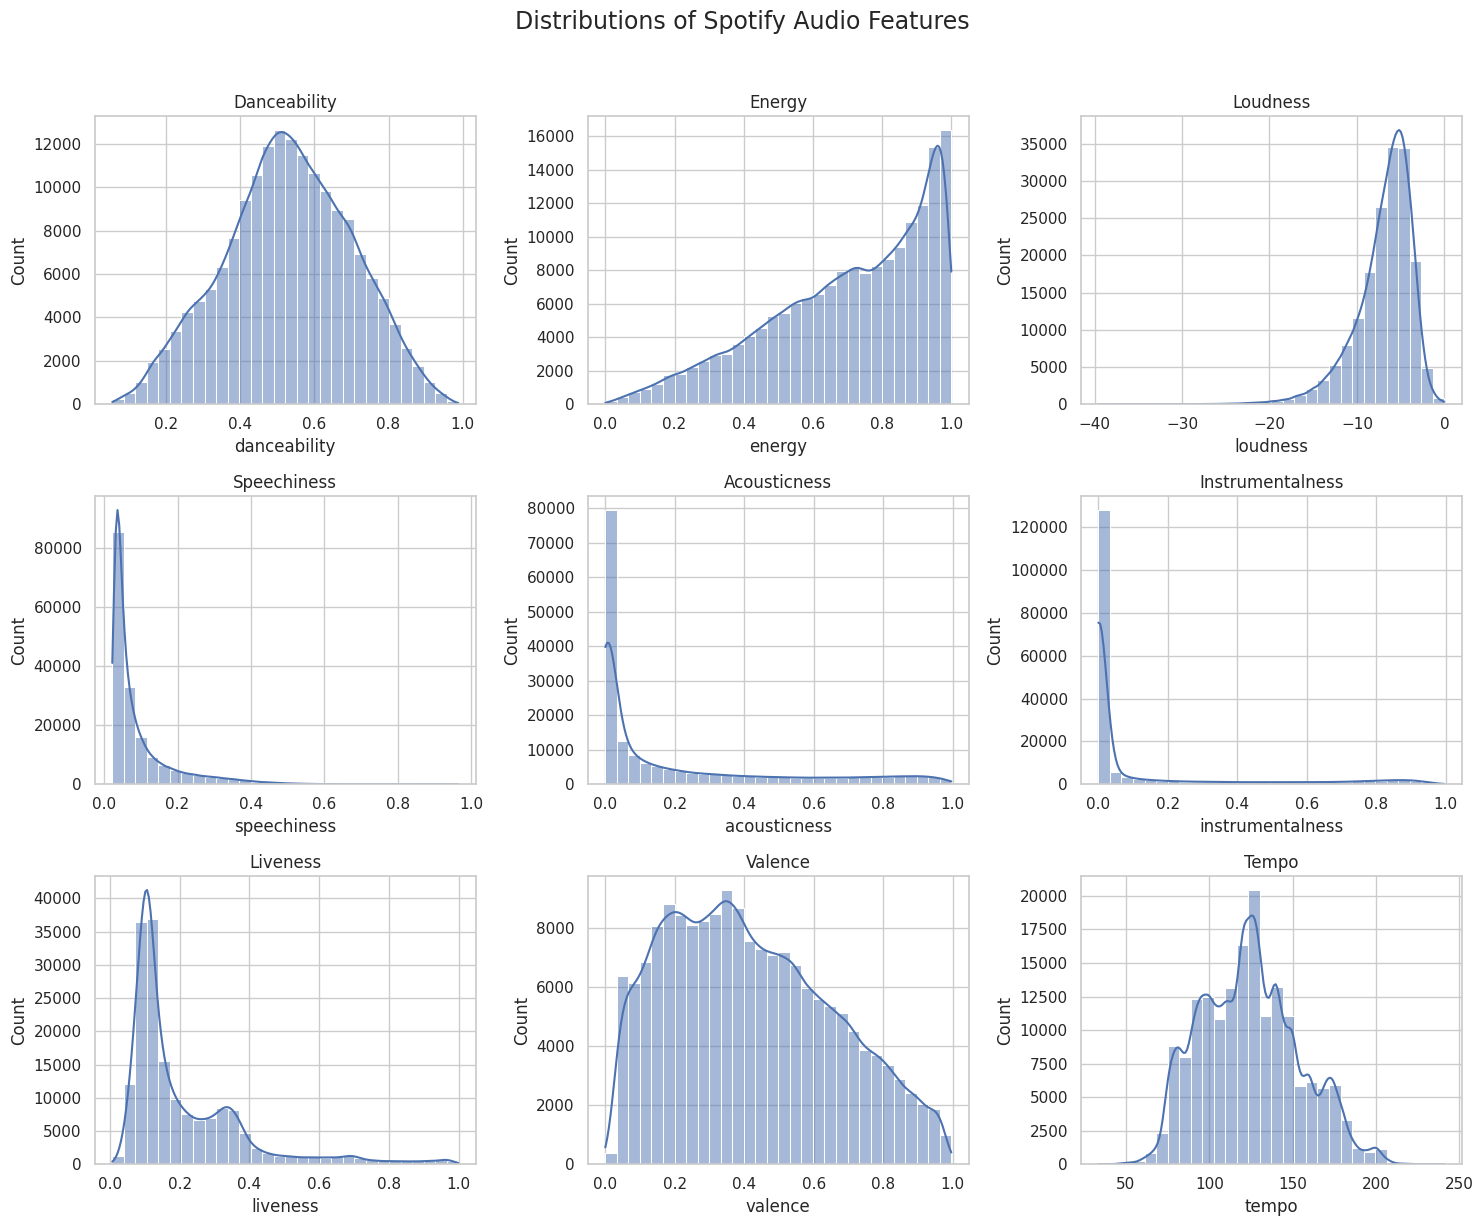

In [12]:
n_features = len(audio_features)

n_cols = 3
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 12)
)

axes = axes.flatten()

for i, feature in enumerate(audio_features):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(feature.replace("_", " ").title())
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Count")

for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Distributions of Spotify Audio Features",
    fontsize=17,
    y=1.02
)

plt.tight_layout()
plt.show()

## 5. Correlation Matrix (Figure 4, right)

Pearson correlations among the nine audio features and popularity are printed and shown as a lower-triangular heat map (red = positive, blue = negative). Strong correlations among features (e.g., energy and loudness, energy and acousticness) indicate overlapping information, so their coefficients must be interpreted jointly.

                  danceability  energy  loudness  speechiness  acousticness  \
danceability            1.0000 -0.1793   -0.0491       0.1061        0.0721   
energy                 -0.1793  1.0000    0.7759       0.1505       -0.7395   
loudness               -0.0491  0.7759    1.0000       0.0914       -0.6062   
speechiness             0.1061  0.1505    0.0914       1.0000       -0.0708   
acousticness            0.0721 -0.7395   -0.6062      -0.0708        1.0000   
instrumentalness       -0.2226  0.1112   -0.0842      -0.0769       -0.0977   
liveness               -0.1471  0.1985    0.1080       0.1210       -0.1072   
valence                 0.4638  0.0846    0.1076       0.0333       -0.0138   
tempo                  -0.1576  0.2154    0.1662       0.0588       -0.1800   
popularity              0.2426 -0.0923    0.0416       0.0606        0.0287   

                  instrumentalness  liveness  valence   tempo  popularity  
danceability               -0.2226   -0.1471   0.4638 

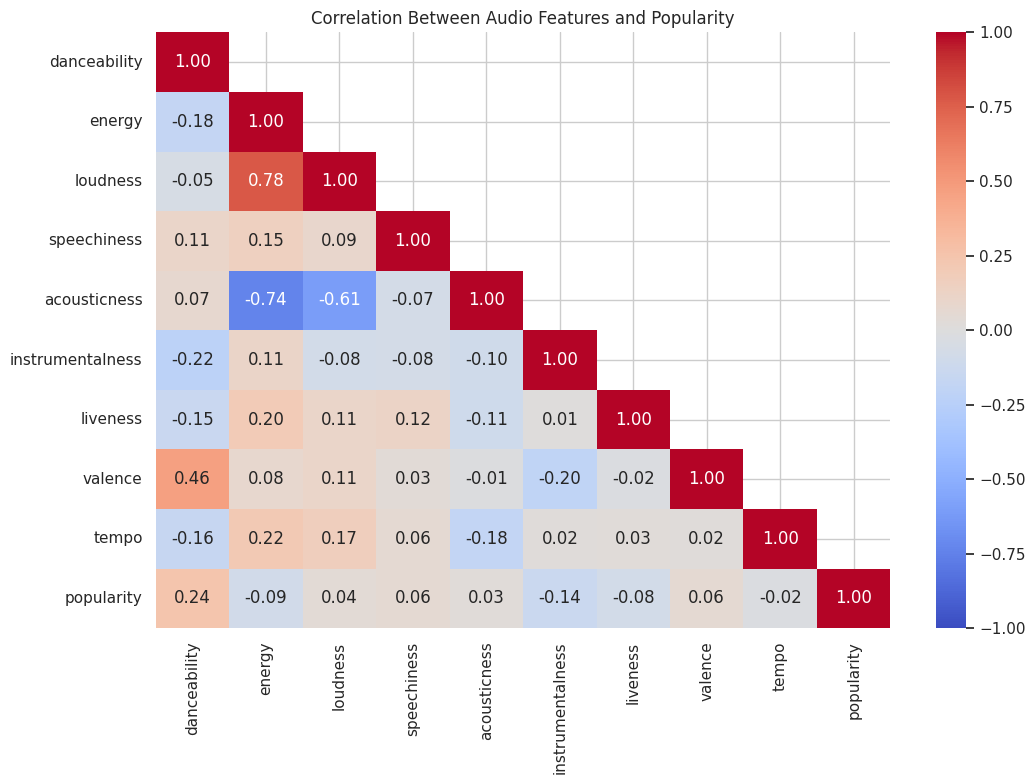

In [13]:
corr_matrix = df[audio_features + ["popularity"]].corr(method="pearson")

print(corr_matrix)

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1
)

plt.title("Correlation Between Audio Features and Popularity")
plt.tight_layout()
plt.show()